In [4]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod_l5 = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/models/model_db_hay/mod'
pth_mod_inh = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/models/fs_internrn_neuron/mod'
pth_data = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/data/interneuron'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/interneurons/'
import os
#os.mkdir(figpth)
from cell_builder_utils import l5_params, _get_dends, _get_pyr_soma, Cell, _get_basket_soma
from hay_mechs_utils import Mechs as l5mechs
from inh_mechs_utils import Mechs as inhmechs
from plot_utils import fig_conductances, fig_compartments
from functools import partial

from hnn_core.viz import plot_cell_morphology

import os
import pandas as pd
from scipy import signal
from plot_utils import fig_conductances, fig_compartments
from matplotlib.gridspec import GridSpec

h.load_file('stdrun.hoc')


1.0

In [5]:
# Build inhibitory cell

section = dict()
section['soma'] = _get_basket_soma()

mech_class = inhmechs(pth_mod_inh)

# Cumberland 2023 and Golomb 2007 parameters
inh_params = {'soma': {'nas': 0.1125*1.5, 
                'kdr': 0.225*.75,
                'kd': 0.00039*10,
                'Ih': 2e-3,
                'pas': {'g': .0001,
                        'e': -70}}}

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/models/fs_internrn_neuron/mod.  Aborting.


In [6]:
inh_allen = pd.read_csv(os.path.join(pth_data, 'ephys_inh.csv'))

# convert AP width to ms

inh_allen.ap_width *= 1000

ephys_measures = dict()

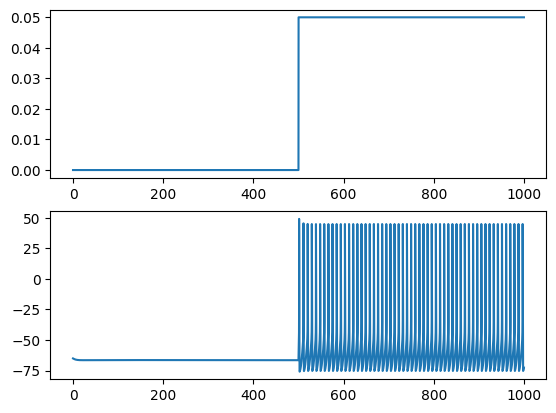

In [7]:
# add stimulation

inh_cell = Cell(section, cell_tree=None, cell_type='Inhibitory', gid=0)
inh_cell.build()
inh_cell = mech_class.add_mechs(inh_cell, inh_params)

stim = h.IClamp(inh_cell._nrn_sections['soma'](0.5))
stim.delay = 500
stim.dur = 500
stim.amp = .05
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
soma_v = h.Vector().record(inh_cell._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.dt = 0.01
h.finitialize(-65 * mV)
h.continuerun(1000 * ms)

fig, ax = plt.subplots(2,1)

ax[0].plot(t,clamp_current)
ax[1].plot(t,soma_v)

# RMP
ephys_measures['RMP'] = soma_v[np.argmin(np.abs(t-500))]
ax[1].plot(t[np.argmin(np.abs(t-500))],soma_v[np.argmin(np.abs(t-500))])

# inhibitory neurons are extremely excitable!



lowest ampl to induce spike: 0.006


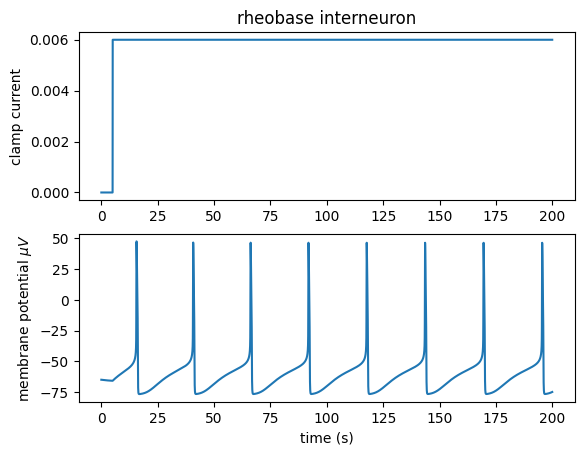

In [8]:
# rheobase
from scipy.signal import find_peaks

ampl = np.arange(0.001,.01,0.005)

for a in ampl:
    inh_cell = Cell(section, cell_tree=None, cell_type='Inhibitory', gid=0)
    inh_cell.build()
    inh_cell = mech_class.add_mechs(inh_cell, inh_params)

    # critical freq
    num_pulse = 3
    stim = h.IClamp(inh_cell._nrn_sections['soma'](0.5))
    stim.delay = 5
    stim.dur = 1000
    stim.amp = a
    clamp_current = h.Vector().record(stim._ref_i)

    v = h.Vector().record(inh_cell._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)


    h.celsius = 37
    h.finitialize(-65 * mV)
    h.continuerun(200 * ms)

    pk = find_peaks(v, height=0)
    if np.any(pk[0]) == True:
        print(f'lowest ampl to induce spike: {a}')
        break

fig, ax = plt.subplots(2,1)

ax[0].plot(t,clamp_current)
ax[0].set_ylabel('clamp current')
ax[1].plot(t,v)
ax[1].set_xlabel('time (s)')
ax[1].set_ylabel('membrane potential $\mu V$')
ax[0].set_title('rheobase interneuron')

fig.savefig(figpth+'rheobase.png')

ValueError: x and y must have same first dimension, but have shapes (20001,) and (100001,)

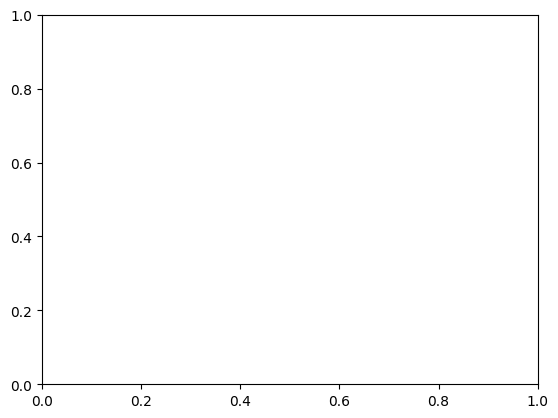

In [9]:
# ISI
from scipy.signal import find_peaks
aps = find_peaks(soma_v,height=0)[0]

fig, ax = plt.subplots()
ax.plot(t,soma_v)
ax.plot(t.as_numpy()[aps], soma_v.as_numpy()[aps], 'o')
ax.set_ylabel('membrane potential $\mu V$')
ax.set_xlabel('time (ms)')
ax.set_xlim([400, 800])
ephys_measures['first_isi'] = np.diff(t.as_numpy()[aps])[0]
ephys_measures['mean_isi'] = np.mean(np.diff(t.as_numpy()[aps]))

fig.savefig(figpth+'spiking.png')


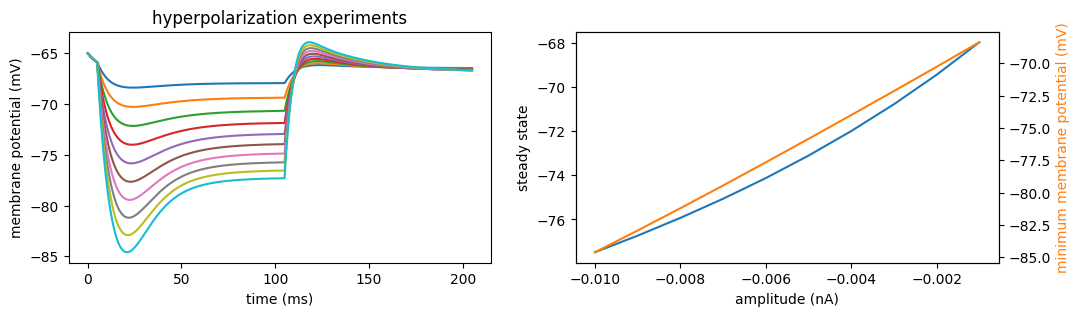

In [19]:
# sag_ratio
from scipy.signal import find_peaks

ampl = np.linspace(-0.001, -.01, 10)

fig, ax = plt.subplots(1,2, figsize = (12, 3))

soma_v = np.zeros((len(ampl),int(1/h.dt*205+1)))
peak_heights = np.zeros_like(ampl)
steady_state = np.zeros_like(ampl)
min_membr_pot = np.zeros_like(ampl)
sag_ratio = np.zeros_like(ampl)
for i,amp in enumerate(ampl):

    inh_cell = Cell(section, cell_tree=None, cell_type='Inhibitory', gid=0)
    inh_cell.build()
    inh_cell = mech_class.add_mechs(inh_cell, inh_params)
    stim = h.IClamp(inh_cell._nrn_sections['soma'](0.5))
    stim.delay = 5
    stim.dur = 100
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(inh_cell._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.dt = 0.01
    h.finitialize(-65 * mV)
    h.continuerun(205 * ms)

    steady_idx = np.argmin(np.abs(t-80))
    soma_v[i] = soma_voltg.as_numpy()
    
    min_membr_pot[i] = np.min(soma_v[i])

    steady_state[i] = soma_v[i][steady_idx]

    ax[0].plot(t, soma_voltg)

ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_xlabel('time (ms)')
ax[0].set_title('hyperpolarization experiments')
ax[1].plot(ampl, steady_state)
ax[1].set_xlabel('amplitude (nA)')
ax[1].set_ylabel('steady state')
ax2 = ax[1].twinx()
ax2.plot(ampl, min_membr_pot, color='tab:orange')
ax2.set_ylabel('minimum membrane potential (mV)', color='tab:orange')

fig.savefig(figpth+'hyperpolarization.png')



In [20]:
# according to Allen documentation
ephys_measures['sag'] = (min_membr_pot-steady_state)/min_membr_pot


## AP measures


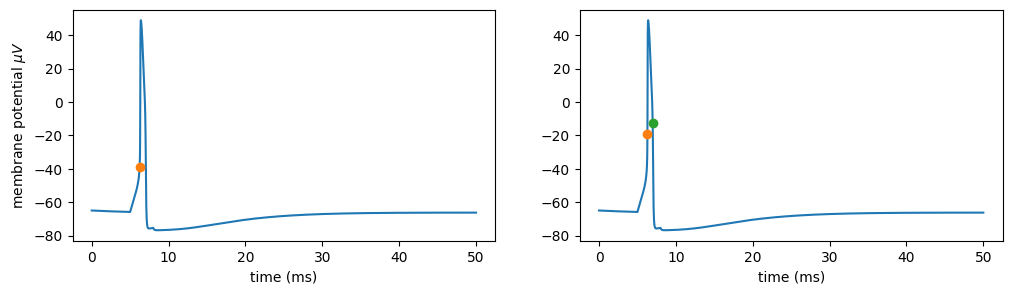

In [26]:
# threshold

inh_cell = Cell(section, cell_tree=None, cell_type='Inhibitory', gid=0)
inh_cell.build()
inh_cell = mech_class.add_mechs(inh_cell, inh_params)

stim = h.IClamp(inh_cell._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 3
stim.amp = .05
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(inh_cell._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.dt = .01
h.finitialize(-65 * mV)
h.continuerun(50 * ms)

fig, ax = plt.subplots(1,2, figsize=(12,3))

ap, properties = find_peaks(v_soma, height=0, width=0)

ax[0].plot(t,v_soma)


v_grad = np.gradient(v_soma)
ap_thresh_idx = np.argmin(np.abs(v_grad-np.max(v_grad)*.05))
ephys_measures['ap_threshold'] = v_soma[ap_thresh_idx]
ax[0].plot(t[ap_thresh_idx], v_soma[ap_thresh_idx],'o')
ax[0].set_ylabel('membrane potential $\mu V$')
ax[0].set_xlabel('time (ms)')


# upstroke: mean of dV/dt between AP threshold and AP peak
 
upstroke = np.max(np.gradient(v_soma.as_numpy()[ap_thresh_idx:int(ap)]))

# downstroke: minimum value of dV/dt between AP peak and trough

ap_trough = np.argmin(v_soma)
downstroke = np.min(np.gradient(v_soma.as_numpy()[int(ap):ap_trough]))

ephys_measures['upstroke_downstroke'] = np.abs(upstroke/downstroke)


# AP width: width at half maximum

half_max = np.min(v_soma.as_numpy()) + (np.max(v_soma.as_numpy())-np.min(v_soma.as_numpy()))/2
idx1 = np.argmin(np.abs(v_soma.as_numpy()[ap_thresh_idx:int(ap)]-half_max))
idx2 = np.argmin(np.abs(v_soma.as_numpy()[int(ap):ap_trough]-half_max))
ax[1].plot(t,v_soma)
ax[1].plot(t.as_numpy()[idx1+ap_thresh_idx],v_soma.as_numpy()[idx1+ap_thresh_idx],'o')
ax[1].plot(t.as_numpy()[idx2+int(ap)],v_soma.as_numpy()[idx2+int(ap)],'o')
ax[1].set_xlabel('time (ms)')

ephys_measures['ap_width'] = t.as_numpy()[idx2+int(ap)]-t.as_numpy()[idx1+ap_thresh_idx]

fig.savefig(figpth+'ap_measures.png')

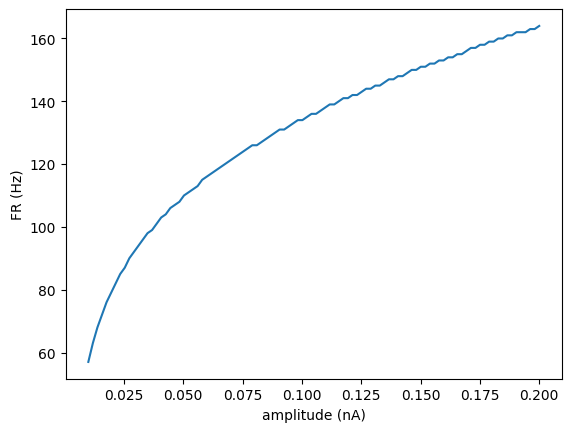

In [23]:
# FR slope
l_stim = 1000

ampl = np.linspace(0.01, .2, 100)

soma_v = np.zeros((len(ampl),int(1/h.dt*l_stim+1)))
fr = np.zeros_like(ampl)

for i,amp in enumerate(ampl):

    inh_cell = Cell(section, cell_tree=None, cell_type='Inhibitory', gid=0)
    inh_cell.build()
    inh_cell = mech_class.add_mechs(inh_cell, inh_params)
    stim = h.IClamp(inh_cell._nrn_sections['soma'](0.5))
    stim.delay = 5
    stim.dur = 1000
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(inh_cell._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.dt = 0.01
    h.finitialize(-65 * mV)
    h.continuerun((l_stim+stim.delay)* ms)

    pk = find_peaks(v_soma, height=0)

    fr[i] = len(pk[0])

fig, ax = plt.subplots()
ax.plot(ampl,fr)
ax.set_ylabel('FR (Hz)')
ax.set_xlabel('amplitude (nA)')

pA = 0.001 # nA (convert nA to pA)
ephys_measures['FR_slope'] = np.polyfit(ampl,fr,1)[0]
ephys_measures['FR_slope'] *= pA

fig.savefig(figpth+'FR_slope.png')


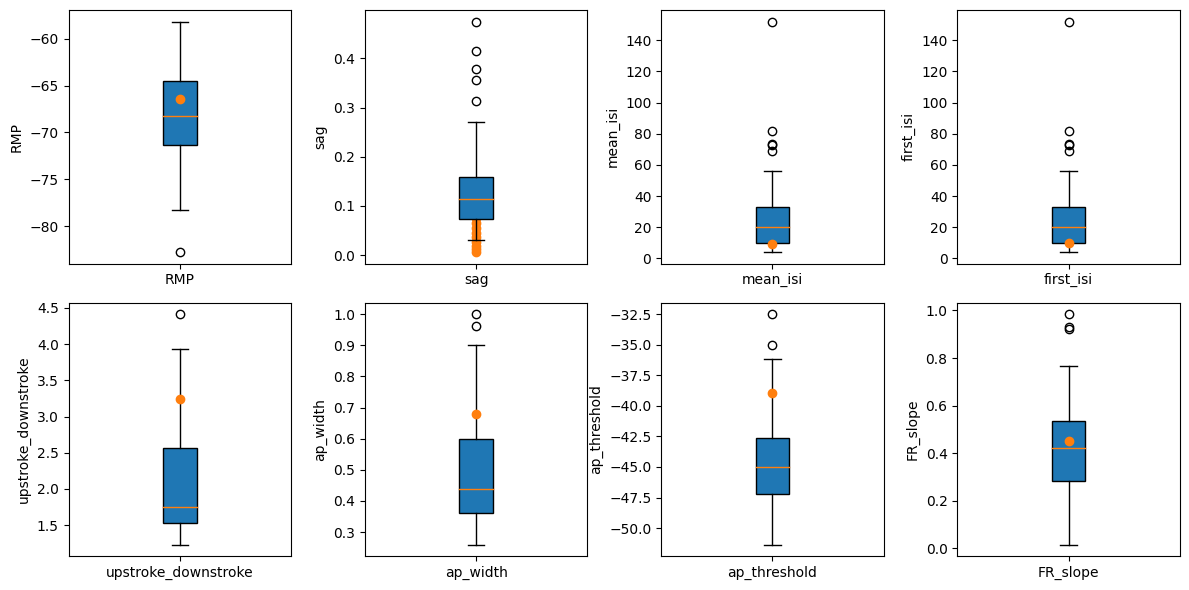

In [27]:
measures = ['RMP', 'sag', 'mean_isi', 'first_isi', 'upstroke_downstroke', 'ap_width', 'ap_threshold', 'FR_slope']

fig, ax = plt.subplots(2,4,figsize=(12,6))
ax = ax.ravel()
for i,m in enumerate(measures):
    ax[i].boxplot(inh_allen[m].dropna(), vert=True, patch_artist=True, labels=[m])

    if m == 'sag':
        ax[i].scatter(np.ones(len(ephys_measures[m])), ephys_measures[m],c='tab:orange', zorder=5)
    else:
        ax[i].plot(1, ephys_measures[m], 'o', color='tab:orange')
    ax[i].set_ylabel(m)

fig.tight_layout()
fig.savefig(figpth+'interneuron_vs_allen.png')